# Multimodal embeddings in a toy vector space
This notebook builds a tiny "map of meaning" where hand-made text vectors and image vectors live in the same space, just like the shared space in a multimodal model. We measure closeness with cosine similarity and use it to search a pretend photo library with a sentence.

## Step 0: The tools
I only need numpy for the maths, pandas for tidy tables and matplotlib for the charts. The random generator is seeded with 42, so you get exactly the same numbers I got.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## Step 1: Cosine similarity, checked against the post
Cosine similarity compares the *direction* of two arrows. You multiply the lists number by number, add it all up (the dot product), then divide by the lengths of both arrows.

Before trusting it on anything new, I check it against the hand calculation from the post. Coffee and espresso should come out near 0.98. Coffee and invoice should come out near 0.11.

In [2]:
def cosine(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

coffee = [0.9, 0.1, 0.0]
espresso = [0.8, 0.2, 0.1]
invoice = [0.1, 0.0, 0.9]

print(f"coffee vs espresso: {cosine(coffee, espresso):.3f}")
print(f"coffee vs invoice:  {cosine(coffee, invoice):.3f}")

coffee vs espresso: 0.984
coffee vs invoice:  0.110


## Step 2: Build a tiny shared space for text and images
A real model like EmbeddingGemma 2 uses 768 numbers per item. I use 4, and I give each one a human name so we can read them: "office", "animal", "food" and "outdoors". A real model learns its own directions, and they usually have no name.

I type in a rough position for each item by hand, then add a little random noise so nothing is perfectly tidy. **These vectors are simulated.** No real model or real photo is involved. The key point: the image vectors and the text vectors use the *same four coordinates*. That is what "one shared space" means.

In [3]:
dims = ["office", "animal", "food", "outdoors"]

image_base = {
    "img: whiteboard (IMG_4471)": [0.9, 0.0, 0.0, 0.1],
    "img: laptop on desk":        [0.7, 0.0, 0.3, 0.0],
    "img: dog in park":           [0.0, 0.9, 0.0, 0.5],
    "img: cat on sofa":           [0.1, 0.9, 0.1, 0.0],
    "img: coffee cup":            [0.1, 0.0, 0.9, 0.1],
    "img: pizza":                 [0.0, 0.0, 0.9, 0.2],
    "img: mountain lake":         [0.0, 0.1, 0.0, 0.9],
    "img: forest trail":          [0.0, 0.2, 0.1, 0.8],
}
text_base = {
    "txt: whiteboard with a server diagram": [1.0, 0.0, 0.0, 0.0],
    "txt: a dog playing outside":            [0.0, 0.8, 0.0, 0.5],
    "txt: a hot cup of coffee":              [0.0, 0.0, 1.0, 0.1],
    "txt: hiking in the mountains":          [0.0, 0.0, 0.0, 1.0],
}

names = list(image_base) + list(text_base)
kinds = ["image"] * len(image_base) + ["text"] * len(text_base)
base = np.array(list(image_base.values()) + list(text_base.values()))
vectors = base + rng.normal(0, 0.05, size=base.shape)

items = pd.DataFrame(vectors, columns=dims, index=names)
items.insert(0, "kind", kinds)
print(items.round(2))

                                        kind  office  animal  food  outdoors
img: whiteboard (IMG_4471)             image    0.92   -0.05  0.04      0.15
img: laptop on desk                    image    0.60   -0.07  0.31     -0.02
img: dog in park                       image   -0.00    0.86  0.04      0.54
img: cat on sofa                       image    0.10    0.96  0.12     -0.04
img: coffee cup                        image    0.12   -0.05  0.94      0.10
img: pizza                             image   -0.01   -0.03  0.96      0.19
img: mountain lake                     image   -0.02    0.08  0.03      0.92
img: forest trail                      image    0.02    0.22  0.21      0.78
txt: whiteboard with a server diagram   text    0.97   -0.04  0.03      0.06
txt: a dog playing outside              text   -0.01    0.76 -0.04      0.53
txt: a hot cup of coffee                text    0.04    0.03  0.97      0.11
txt: hiking in the mountains            text    0.01    0.01  0.04      1.01

## Step 3: Look at the map
Four dimensions are already too many to draw, so I squash them down to two with a classic trick called PCA. It keeps the two directions where the items differ the most. The picture is an approximation, but it shows the idea well.

Look for the neighbourhoods. Each sentence (orange triangle) should sit right next to the photos (blue dots) it describes, even though one is text and the other is pixels.

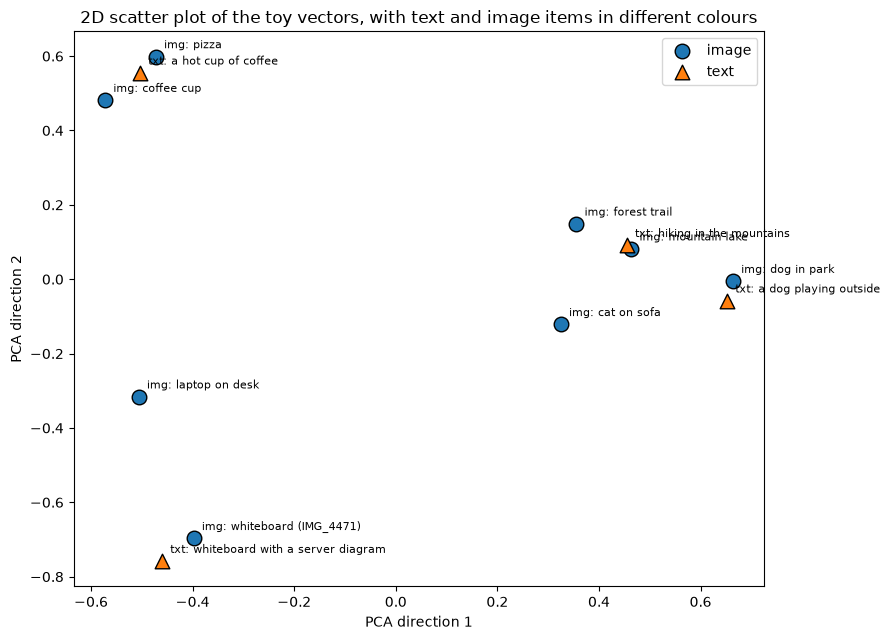

In [4]:
centered = vectors - vectors.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
coords = centered @ vt[:2].T

plt.figure(figsize=(9, 6.5))
for kind, color, marker in [("image", "tab:blue", "o"), ("text", "tab:orange", "^")]:
    mask = items["kind"].values == kind
    plt.scatter(coords[mask, 0], coords[mask, 1], c=color, marker=marker, s=110,
                label=kind, edgecolors="black")
for name, (x, y) in zip(names, coords):
    plt.annotate(name, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=8)
plt.xlabel("PCA direction 1")
plt.ylabel("PCA direction 2")
plt.legend()
plt.title("2D scatter plot of the toy vectors, with text and image items in different colours")
plt.tight_layout()
plt.show()

## Step 4: Compare every item with every other item
Now I compute cosine similarity for every pair. A neat shortcut: if I first scale every vector to length 1, the cosine is just the dot product, so one matrix multiplication gives me the whole table.

In the heatmap, bright squares mean "pointing the same way". You should see bright blocks where a sentence meets its matching photos, and dark squares between unrelated things, like pizza and a mountain lake.

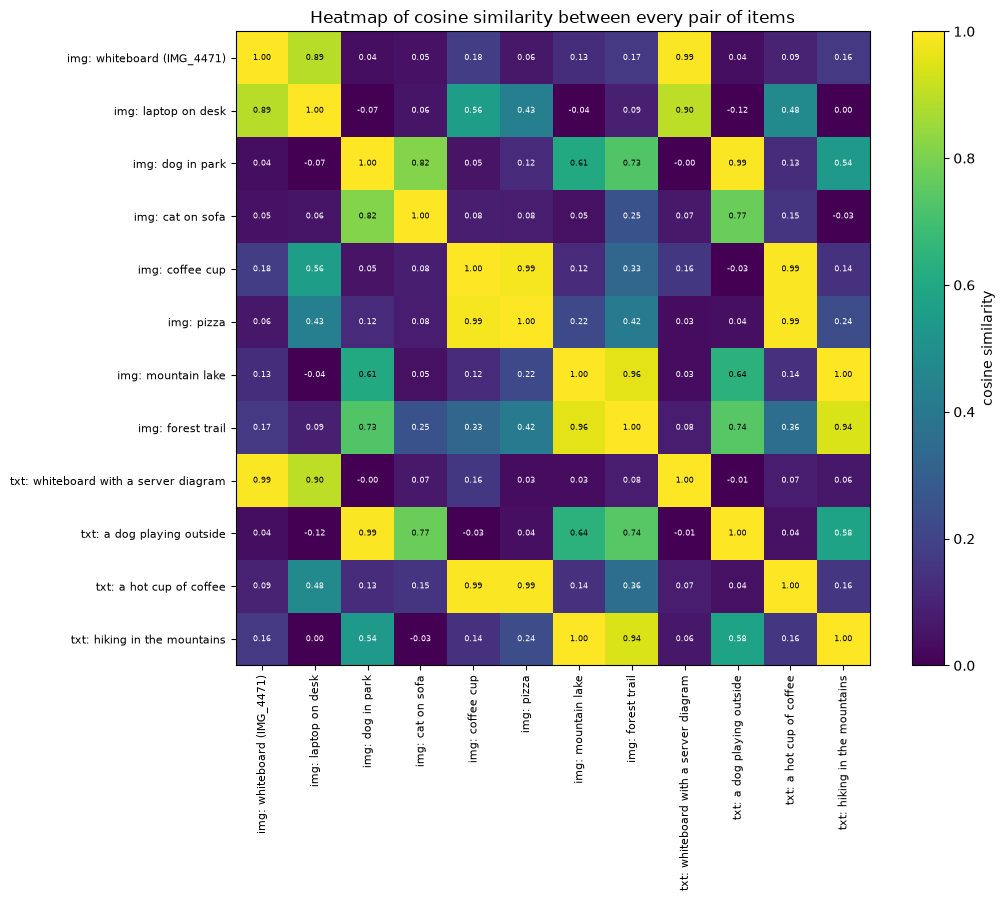

txt: whiteboard with a server diagram    -> closest photo: img: whiteboard (IMG_4471) (0.995)
txt: a dog playing outside               -> closest photo: img: dog in park (0.995)
txt: a hot cup of coffee                 -> closest photo: img: pizza (0.994)
txt: hiking in the mountains             -> closest photo: img: mountain lake (0.996)


In [5]:
unit = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
sim = unit @ unit.T
sim_df = pd.DataFrame(sim, index=names, columns=names)

plt.figure(figsize=(11, 9))
plt.imshow(sim, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="cosine similarity")
plt.xticks(range(len(names)), names, rotation=90, fontsize=8)
plt.yticks(range(len(names)), names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        plt.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=6,
                 color="black" if sim[i, j] > 0.6 else "white")
plt.title("Heatmap of cosine similarity between every pair of items")
plt.tight_layout()
plt.show()

image_names = list(image_base)
for t in text_base:
    best = sim_df.loc[t, image_names].idxmax()
    print(f"{t:40s} -> closest photo: {best} ({sim_df.loc[t, best]:.3f})")

## Step 5: Search the photos with a sentence
This is the moment from the post. I take my query, "whiteboard with a server diagram", and rank every photo by its cosine score against it. No words are matched, no file names are read. We just look for the arrows pointing closest to the query's arrow.

If the toy space works, IMG_4471 wins. The laptop photo should come second, because it shares the "office" direction, and the dog and the lake should trail far behind.

Query: txt: whiteboard with a server diagram
  1. img: whiteboard (IMG_4471)   0.995
  2. img: laptop on desk          0.901
  3. img: coffee cup              0.162


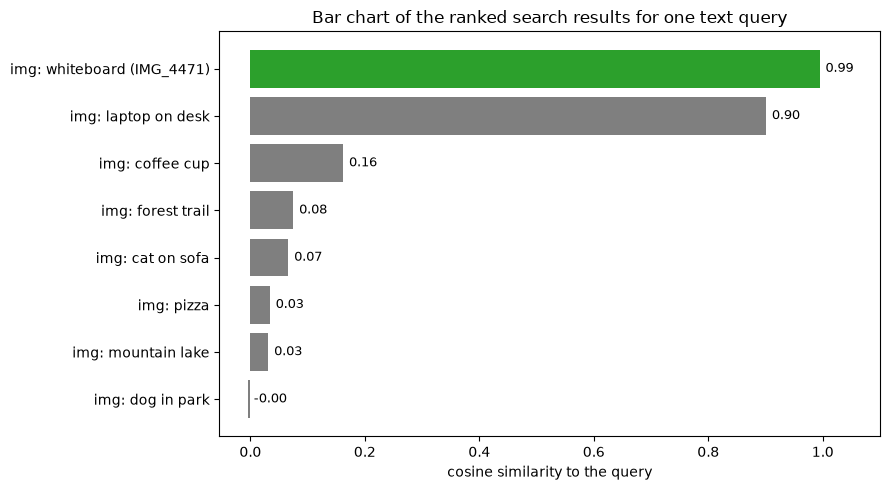

In [6]:
query = "txt: whiteboard with a server diagram"
scores = sim_df.loc[query, image_names].sort_values(ascending=False)

print(f"Query: {query}")
for rank, (name, score) in enumerate(scores.head(3).items(), start=1):
    print(f"  {rank}. {name:28s} {score:.3f}")

colors = ["tab:green"] + ["tab:gray"] * (len(scores) - 1)
plt.figure(figsize=(9, 5))
plt.barh(scores.index[::-1], scores.values[::-1], color=colors[::-1])
for y, v in enumerate(scores.values[::-1]):
    plt.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9)
plt.xlabel("cosine similarity to the query")
plt.xlim(min(0, scores.min()) - 0.05, 1.1)
plt.title("Bar chart of the ranked search results for one text query")
plt.tight_layout()
plt.show()

## What to take away
That is the whole loop: put text and images on one map, compare directions with cosine similarity, sort by score. A real multimodal model does the same thing with 768 learned numbers instead of my 4 hand-typed ones, and it figures out where a photo belongs by looking at the pixels.

One warning from the post still applies here. The exact scores depend entirely on the model (in this case, on me and my typing). Look at the *ranking* on your own data instead of trusting a fixed cutoff. Try changing the query vector in Step 5, or raise the noise in Step 2 from 0.05 to 0.3, and watch how quickly the neat neighbourhoods start to blur.